# NSL-KDD: evaluation on the official test set
`attack-detection.ipynb` splits `KDDTrain+` 75/25, so its test rows come from the same distribution as training and scores are very high. This notebook uses the **official protocol**: train on `KDDTrain+`, test on the separate `KDDTest+` file (which contains attacks not seen in training). Expect lower, more realistic scores.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, accuracy_score

In [2]:
cols = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot",
 "num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations","num_shells",
 "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
 "rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count",
 "dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
 "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]
train = pd.read_csv('data/KDDTrain+.txt', names=cols).drop(columns='difficulty')
test  = pd.read_csv('data/KDDTest+.txt',  names=cols).drop(columns='difficulty')
print(train.shape, test.shape)
print('Attack names in test but not in train:', sorted(set(test.label) - set(train.label)))

(125973, 42) (22544, 42)
Attack names in test but not in train: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


## Preprocessing
One-hot encode categorical columns on train+test together so both have identical columns; binary target: 0 = normal, 1 = attack.

In [3]:
cat = ['protocol_type', 'service', 'flag']
both = pd.get_dummies(pd.concat([train, test], keys=['tr', 'te']).drop(columns='label'), columns=cat)
X_train, X_test = both.loc['tr'].astype(float), both.loc['te'].astype(float)
y_train = (train.label != 'normal').astype(int)
y_test  = (test.label  != 'normal').astype(int)
print('Train attack share: %.1f%%  | Test attack share: %.1f%%' % (100*y_train.mean(), 100*y_test.mean()))

Train attack share: 46.5%  | Test attack share: 56.9%


## Models

In [4]:
models = {
 'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
 'KNN (k=5)':           make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
 'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}
rows, preds = [], {}
for n, m in models.items():
    m.fit(X_train, y_train); p = m.predict(X_test); preds[n] = p
    rows.append({'Model': n, 'Accuracy': accuracy_score(y_test, p), 'F1 (attack)': f1_score(y_test, p)})
res = pd.DataFrame(rows).set_index('Model').round(3).sort_values('F1 (attack)', ascending=False); res

,Accuracy,F1 (attack)
Model,,
KNN (k=5),0.770,0.763
Random Forest,0.768,0.750
Logistic Regression,0.754,0.743


KNN (k=5)
              precision    recall  f1-score   support

      normal       0.67      0.93      0.78      9711
      attack       0.92      0.65      0.76     12833

    accuracy                           0.77     22544
   macro avg       0.80      0.79      0.77     22544
weighted avg       0.81      0.77      0.77     22544



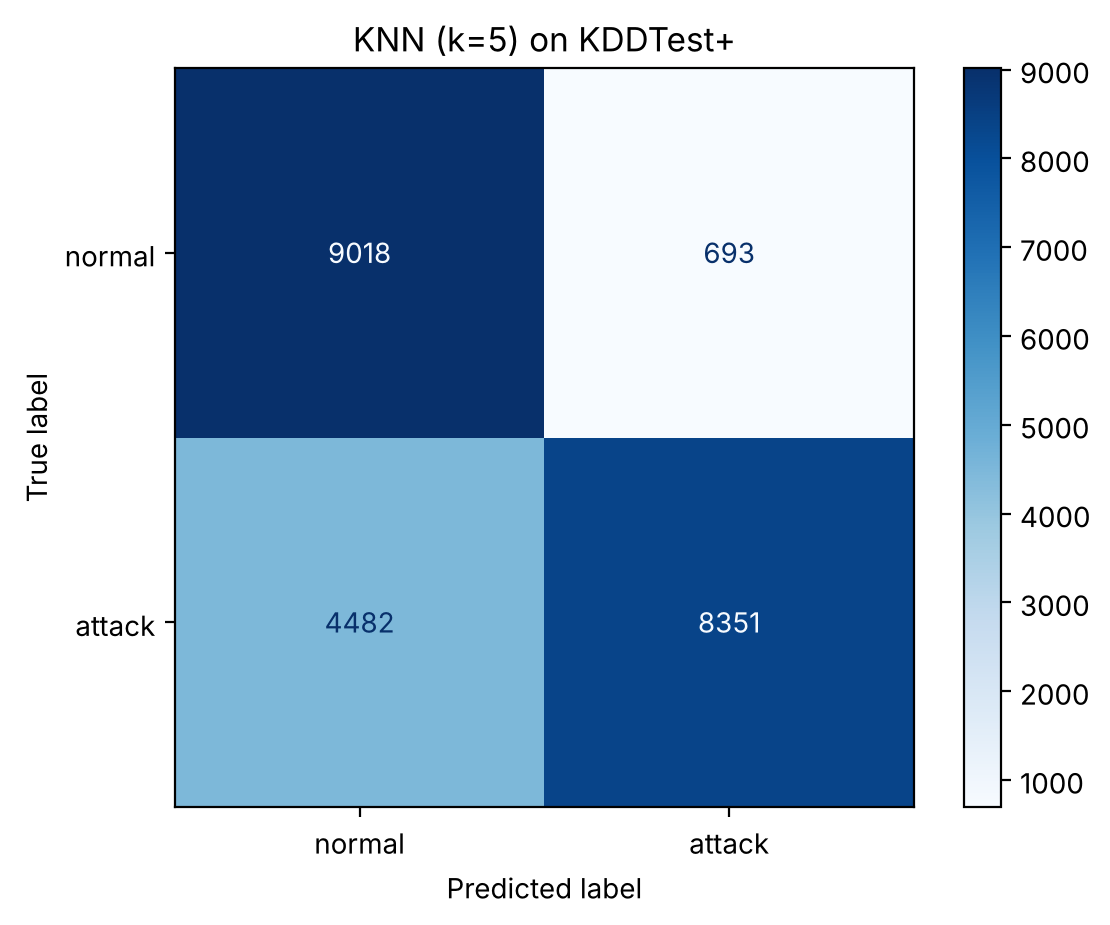

In [5]:
best = res.index[0]
print(best); print(classification_report(y_test, preds[best], target_names=['normal', 'attack']))
ConfusionMatrixDisplay.from_predictions(y_test, preds[best], display_labels=['normal', 'attack'], cmap='Blues')
plt.title(f'{best} on KDDTest+'); plt.show()

## Takeaway
Scores on the official `KDDTest+` are clearly lower than the 97-99% from a random split of `KDDTrain+`, because the test set contains attack types absent from training. A random split of the training file therefore overstates real-world performance. Missed attacks (false negatives) are the costly error for an IDS, so recall on the attack class is the number to watch.